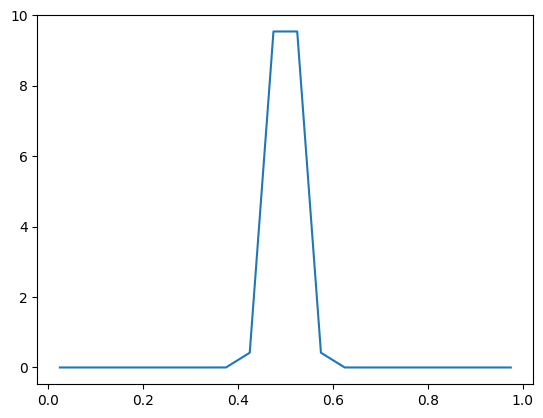

In [3]:
import numpy as np
import matplotlib.pyplot as plt

n_cells = 20

dt = 0.01
D = 0.04
sigma2 = 2 * D * dt

x0 = 0.50

x_borders = np.linspace(0, 1, n_cells + 1)
x_centers = 0.5 * (x_borders[:-1] + x_borders[1:])

density = 1.0 / np.sqrt(2 * np.pi * sigma2) * np.exp(-0.5 * (x_centers - x0)**2 / sigma2)

plt.plot(x_centers, density)
plt.show()

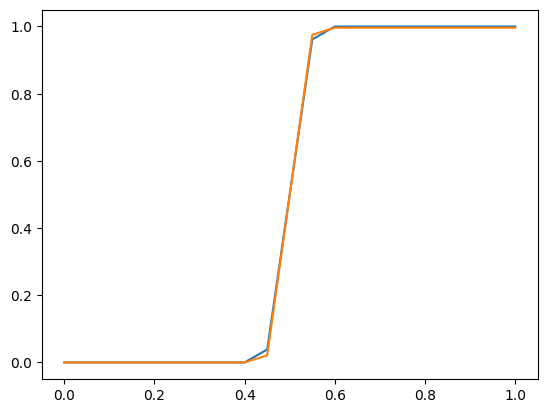

In [4]:
# construct the cumulative distribution function

# calculate cdf using analytical formula
import math
cdf = np.zeros(n_cells+1)
for i in range(n_cells+1):
    cdf[i] = 0.5 + 0.5 * math.erf((x_borders[i] - x0) / np.sqrt(2 * sigma2))

# calculate cdf by summing up the density
cdf2 = np.zeros(n_cells+1)
cdf2[0] = 0
for i in range(1, n_cells+1):
    cdf2[i] = cdf2[i-1] + density[i-1] * (x_borders[i] - x_borders[i-1])


plt.plot(x_borders, cdf)
plt.plot(x_borders, cdf2)
plt.show()


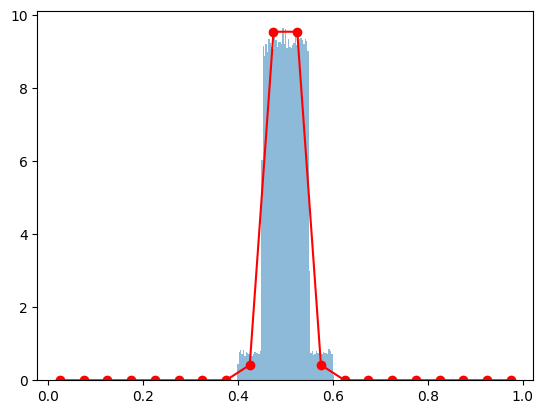

In [8]:
# Sample from the distribution

n_samples = 100000

samples = np.zeros(n_samples)

for i in range(n_samples):
    r = np.random.rand()
    for j in range(n_cells):
        if cdf[j] <= r and r < cdf[j+1]:
            # cdf is a linear interpolation between cdf[j] and cdf[j+1]
            # find the x value that corresponds to r

            x = x_borders[j] + (r - cdf[j]) / (cdf[j+1] - cdf[j]) * (x_borders[j+1] - x_borders[j])
            samples[i] = x
            break

plt.plot(x_centers, density, "r-o")
plt.hist(samples, bins=100, density=True, alpha=0.5)
plt.show()